# 03 — Как искали признаки

Ноутбук описывает последовательность проверок признаков: что проверяли, какими
средствами и что получилось. Каждый шаг — воспроизводимый расчёт по данным.

Код весь внутри ноутбука: он запускается автономно, без обращения к пакетам
проекта, и всё, что ниже, — самостоятельные ячейки над данными.

## Протокол измерения

**Единица анализа — заявка.** Одна строка истории — кредитный продукт; `id`
идентифицирует заявку, а не человека. Поскольку клиентского идентификатора в данных нет,
проверить повторные заявки одного человека нельзя.

**Обучение и CV.** Всё, что связано с выбором, считается на заявках `id < 2M`.
Внутри этого отрезка — expanding-window CV по фолдам 2–7: на фолде `k` модель
учится на всех заявках с `id < k · 250 000`, а проверяется на следующих
250 000. Кодировка уровней — OOF: партиция `k` кодируется статистикой партиций
`0…k-1`. Партиция 0 не имеет предыдущих партиций для OOF-статистики, поэтому
все кодированные признаки получают нейтральный ноль, а бинарный `cold_start = 1`
явно говорит модели: «нет предыдущих OOF-партиций». Это не то же самое, что
«нет истории»: агрегаты по истории партиции 0 всё равно используются. Без флага
модель не могла бы отличить отсутствие OOF-статистики от нулевой статистики.

**Холдаут.** Отрезок `[2M, 3M)` не участвует в выборе признаков, гиперпараметров
и варианта набора. Метки холдаута читаются один раз — в финальной ячейке оценки,
и только для AUC. На нём даётся одна оценка уже зафиксированного набора по
восьми блокам по 125 000 заявок; результат докладывается средним и SD, а не
одним числом. Повторной подстройки по холдауту нет.

**Лестница признаков.** Сравниваются четыре вложенных набора:
`control` → `plus_counts` → `plus_recent_overdue` → `plus_weighted_ladder`.
`control` — только агрегаты без просрочек; `plus_counts` добавляет счётчики
просрочек; `plus_recent_overdue` — `any_overdue` и `any_overdue_last3`;
`plus_weighted_ladder` — `overdue_ladder`, `overdue_sev`, `overdue_sev530`.
Ступень принимается, если средний прирост больше SE и положителен не
меньше чем в 5 из 6 фолдов. Затем
проверяются два упрощения: убрать `n_records` и убрать `first_*`/`PAYM_first`.
Варианта `full` нет: отвергнутые ступени не возвращаются в набор. Сырые коды
последней записи исключены до прогона: это случайные метки продуктов, а не риск.

**Модель.** `HistGradientBoostingClassifier` с фиксированными гиперпараметрами,
`early_stopping=False`, `max_iter=300`. 300 — это бюджет итераций, а не
доказательство сходимости: ранняя остановка не используется, потому что она
отбирает деревья по внутренней validation-выборке и делает сравнение вариантов
менее прозрачным.

**Что служит эталоном.** Первые шаги проверяют исходные предположения; последние
сравнивают варианты признаков между собой. Расчёты ниже выполняются по данным;
числа из пересказа не используются.


In [1]:
from __future__ import annotations

import gc
import json
import resource
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score


def find_repo_root() -> Path:
    """Ищет корень репозитория по pyproject.toml: ноутбук работает из любого каталога внутри репозитория."""
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise RuntimeError("Не найден корень репозитория: нет pyproject.toml вверх по дереву")


REPO_ROOT = find_repo_root()


def rel(path: Path) -> str:
    """Путь относительно корня репозитория: чтобы в выводах не печатался абсолютный путь."""
    try:
        return str(Path(path).resolve().relative_to(REPO_ROOT))
    except ValueError:
        return Path(path).name


def part_key(path: Path) -> tuple[int, str]:
    digits = "".join(character for character in path.stem if character.isdigit())
    return (int(digits) if digits else -1, path.name)


def peak_memory_gb() -> float:
    peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return peak / 2**30 if sys.platform == "darwin" else peak / 2**20


def fmt_int(value: int) -> str:
    """Число с пробелами между тысячами; запятые в тексте не трогает."""
    return f"{value:,}".replace(",", " ")


DATA_DIR = REPO_ROOT / "data" / "raw" / "data_for_competition"
TRAIN_PARTS = sorted((DATA_DIR / "train_data").glob("train_data_*.pq"), key=part_key)
TEST_PARTS = sorted((DATA_DIR / "test_data").glob("test_data_*.pq"), key=part_key)
FEATURES = [name for name in pq.ParquetFile(TRAIN_PARTS[0]).schema_arrow.names if name != "id"]
assert len(TRAIN_PARTS) == 12 and len(TEST_PARTS) == 2

ALPHA = 200.0
MIN_LEVEL_ROWS = 2000
FIT_MAX = 2_000_000
COLD_START_PART = 0
SEED = 42
PART_SIZE = 250_000
FOLD_FIRST, FOLD_LAST = 2, 7  # фолды 2..7 включительно
HOLDOUT_BLOCKS = [
    (2_000_000 + index * 125_000, 2_000_000 + (index + 1) * 125_000) for index in range(8)
]
HGB_PARAMS = dict(
    max_iter=300,
    learning_rate=0.08,
    min_samples_leaf=200,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=SEED,
)

TARGETS_FIT = pd.read_csv(DATA_DIR / "train_target.csv", nrows=FIT_MAX)
assert len(TARGETS_FIT) == FIT_MAX
assert TARGETS_FIT["id"].is_monotonic_increasing, "train_target.csv должен идти по возрастанию id"
assert int(TARGETS_FIT["id"].iloc[-1]) == FIT_MAX - 1
FLAGS_FIT = TARGETS_FIT.set_index("id")["flag"]
assert FLAGS_FIT.notna().all()
assert FLAGS_FIT.size == FIT_MAX
BASE_RATE = float(FLAGS_FIT.mean())

print(f"корень:           {REPO_ROOT.name}")
print(f"данные:           {rel(DATA_DIR)}")
print(f"train-партиций:   {len(TRAIN_PARTS)}, test-партиций: {len(TEST_PARTS)}")
print(f"обучение и CV:    id <  {fmt_int(FIT_MAX)}")
print(
    f"CV:               expanding-window, фолды {FOLD_FIRST}..{FOLD_LAST} "
    f"по {fmt_int(PART_SIZE)} заявок"
)
holdout_range = f"[{fmt_int(2_000_000)}, {fmt_int(3_000_000)})"
print(f"холдаут:          восемь блоков по 125 000 в {holdout_range}")
print(f"базовая доля заявок id < 2M: {BASE_RATE:.4f}")


корень:           kaggle-creditscore-alfa
данные:           data/raw/data_for_competition
train-партиций:   12, test-партиций: 2
обучение и CV:    id <  2 000 000
CV:               expanding-window, фолды 2..7 по 250 000 заявок
холдаут:          восемь блоков по 125 000 в [2 000 000, 3 000 000)
базовая доля заявок id < 2M: 0.0362


## Сигнал и его дрейф

Прежде чем строить признаки, нужно решить, как проверять модель. Признак может быть
связан с `flag` на всей истории и при этом терять связь к концу периода: тогда
случайное разбиение может дать завышенный AUC, а на свежих данных качество упадёт.

Всё в этом разделе считается внутри fit — на заявках `id < 2M`, потоково по одной
партиции train в памяти; test здесь не участвует:

- насколько сильно признак связан с целью — Cramér's V с бинарным `flag`;
- как эта связь меняется во времени — V внутри четырёх равных частей заявок по `id`;
- насколько сдвигается само распределение уровней — TV между соседними четвертями
  (основная метрика) и PSI между крайними (вспомогательная, сглаженная).

Измерения ниже показывают, что связь с целью и распределения уровней меняются от
ранних заявок к поздним: у всех 15 сильнейших признаков V в четвёртой четверти
ниже, чем в первой, медиана `TV_макс` — 0.0108, а у трёх признаков из 60
`TV_макс >= 0.05`. Поэтому обучение идёт на `id < 2M`, а проверка — на более
позднем отрезке.


заявок fit по четвертям: [500000, 500000, 499999, 500001] (сумма 2 000 000)
счётчики уровней по 60 признакам собраны за 25s
пик памяти: 3.00 ГБ

сила связи признака с flag, fit (id < 2M), топ-15:
V инвариантна к перенумерации уровней; взвешено по строкам истории
                   признак  cramers_v
pre_loans_credit_cost_rate     0.0603
     enc_loans_credit_type     0.0537
          pre_since_opened     0.0511
                enc_paym_2     0.0496
                enc_paym_3     0.0470
                enc_paym_1     0.0469
                enc_paym_4     0.0440
                enc_paym_5     0.0413
                  pre_util     0.0405
                enc_paym_6     0.0380
                 pre_fterm     0.0369
                enc_paym_7     0.0365
    pre_loans_credit_limit     0.0361
                enc_paym_0     0.0346
                enc_paym_8     0.0345


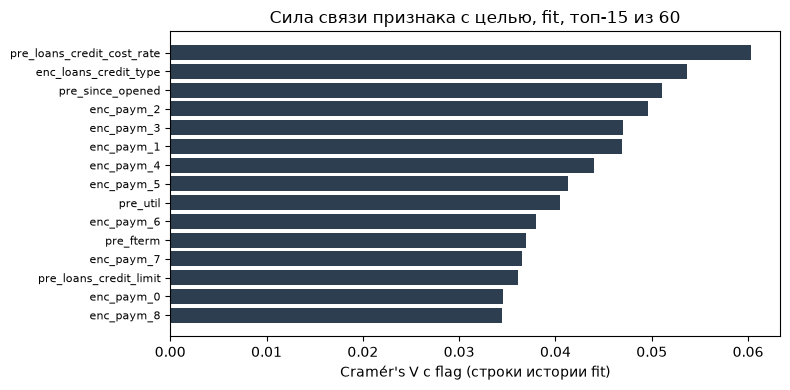

In [2]:
FIT_IDS = FLAGS_FIT.index.to_numpy()
assert len(FIT_IDS) == FIT_MAX
APPLICATION_QUARTILES = FIT_IDS[
    [round(cut * (len(FIT_IDS) - 1)) for cut in (0.0, 0.25, 0.5, 0.75, 1.0)]
]


def grow_levels(table: np.ndarray, size: int) -> np.ndarray:
    """Дополняет накопленные счётчики до нужного числа уровней: уровни только добавляются."""
    if table.shape[-1] >= size:
        return table
    pad = [(0, 0)] * (table.ndim - 1) + [(0, size - table.shape[-1])]
    return np.pad(table, pad)


def cramers_v(table: np.ndarray) -> float:
    """Cramér's V таблицы сопряжённости; для бинарного flag равен sqrt(χ²/n)."""
    table = table.astype(np.float64)
    table = table[table.sum(axis=1) > 0]
    table = table[:, table.sum(axis=0) > 0]
    if table.sum() == 0 or min(table.shape) < 2:
        return float("nan")
    expected = table.sum(axis=1, keepdims=True) * table.sum(axis=0, keepdims=True) / table.sum()
    chi_square = (((table - expected) ** 2) / expected).sum()
    return float(np.sqrt(chi_square / table.sum() / (min(table.shape) - 1)))


started = time.perf_counter()
level_rows = {column: np.zeros(0, dtype=np.int64) for column in FEATURES}
level_positives = {column: np.zeros(0, dtype=np.float64) for column in FEATURES}
quarter_rows = {column: np.zeros((4, 0), dtype=np.int64) for column in FEATURES}
quarter_positives = {column: np.zeros((4, 0), dtype=np.float64) for column in FEATURES}
quarter_applications = np.zeros(4, dtype=np.int64)

for part in TRAIN_PARTS[:8]:
    frame = pd.read_parquet(part).astype(np.int32)
    ids = frame["id"].to_numpy()
    labels = FLAGS_FIT.reindex(ids).to_numpy(dtype=np.float64)
    quartile = np.searchsorted(APPLICATION_QUARTILES[1:-1], ids, side="right")
    first_rows = frame["rn"].to_numpy() == 1
    assert int(first_rows.sum()) == PART_SIZE
    quarter_applications += np.bincount(quartile[first_rows], minlength=4)
    for column in FEATURES:
        values = frame[column].to_numpy()
        size = int(values.max()) + 1
        shift = quartile * size + values
        level_rows[column] = grow_levels(level_rows[column], size)
        level_rows[column][:size] += np.bincount(values, minlength=size)
        level_positives[column] = grow_levels(level_positives[column], size)
        level_positives[column][:size] += np.bincount(values, weights=labels, minlength=size)
        quarter_rows[column] = grow_levels(quarter_rows[column], size)
        quarter_rows[column][:, :size] += np.bincount(shift, minlength=4 * size).reshape(4, size)
        quarter_positives[column] = grow_levels(quarter_positives[column], size)
        quarter_positives[column][:, :size] += np.bincount(
            shift, weights=labels, minlength=4 * size
        ).reshape(4, size)
    del frame
    gc.collect()

assert int(quarter_applications.sum()) == FIT_MAX
print(
    f"заявок fit по четвертям: {quarter_applications.tolist()} "
    f"(сумма {fmt_int(int(quarter_applications.sum()))})"
)
print(f"счётчики уровней по {len(FEATURES)} признакам собраны за {time.perf_counter() - started:.0f}s")
print(f"пик памяти: {peak_memory_gb():.2f} ГБ")

signal_rows = []
for column in FEATURES:
    counts = level_rows[column]
    positives = level_positives[column]
    visible = counts > 0
    table = np.vstack([counts[visible] - positives[visible], positives[visible]])
    signal_rows.append({"признак": column, "cramers_v": round(cramers_v(table), 4)})
signal = pd.DataFrame(signal_rows).sort_values("cramers_v", ascending=False)

print("\nсила связи признака с flag, fit (id < 2M), топ-15:")
print("V инвариантна к перенумерации уровней; взвешено по строкам истории")
print(signal.head(15).to_string(index=False))

figure, axis = plt.subplots(figsize=(8, 4))
top = signal.head(15).iloc[::-1]
axis.barh(np.arange(len(top)), top["cramers_v"], color="#2c3e50")
axis.set_yticks(np.arange(len(top)), top["признак"], fontsize=8)
axis.set_xlabel("Cramér's V с flag (строки истории fit)")
axis.set_title("Сила связи признака с целью, fit, топ-15 из 60")
figure.tight_layout()
plt.show()


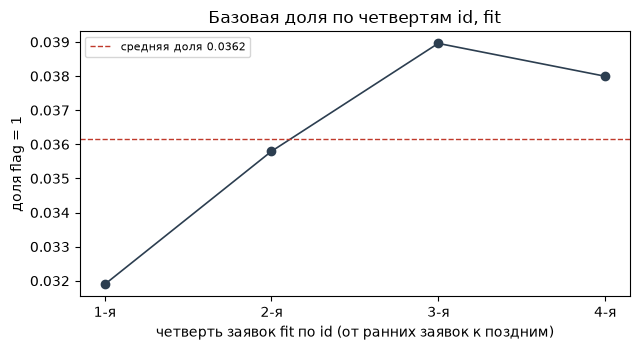

доля flag=1 по четвертям fit: 0.0319, 0.0358, 0.0390, 0.0380
размах по четвертям: 0.0319..0.0390, средняя 0.0362
в 20 равных корзинах fit размах шире: 0.0305..0.0415


In [3]:
application_ids = FLAGS_FIT.index.to_numpy()
application_flags = FLAGS_FIT.to_numpy()
application_quarter = np.searchsorted(APPLICATION_QUARTILES[1:-1], application_ids, side="right")
rate = np.bincount(application_quarter, weights=application_flags, minlength=4) / np.bincount(
    application_quarter, minlength=4
)
fine = application_ids * 20 // (application_ids.max() + 1)
fine_rate = np.bincount(fine, weights=application_flags, minlength=20) / np.bincount(fine, minlength=20)

figure, axis = plt.subplots(figsize=(6.5, 3.6))
positions = np.arange(4)
axis.plot(positions, rate, marker="o", color="#2c3e50", linewidth=1.2)
axis.axhline(
    BASE_RATE,
    color="#c0392b",
    linestyle="--",
    linewidth=1,
    label=f"средняя доля {BASE_RATE:.4f}",
)
axis.set_xticks(positions)
axis.set_xticklabels(["1-я", "2-я", "3-я", "4-я"])
axis.set_xlabel("четверть заявок fit по id (от ранних заявок к поздним)")
axis.set_ylabel("доля flag = 1")
axis.set_title("Базовая доля по четвертям id, fit")
axis.legend(fontsize=8)
figure.tight_layout()
plt.show()

print("доля flag=1 по четвертям fit:", ", ".join(f"{value:.4f}" for value in rate))
print(f"размах по четвертям: {rate.min():.4f}..{rate.max():.4f}, средняя {rate.mean():.4f}")
print(f"в 20 равных корзинах fit размах шире: {fine_rate.min():.4f}..{fine_rate.max():.4f}")


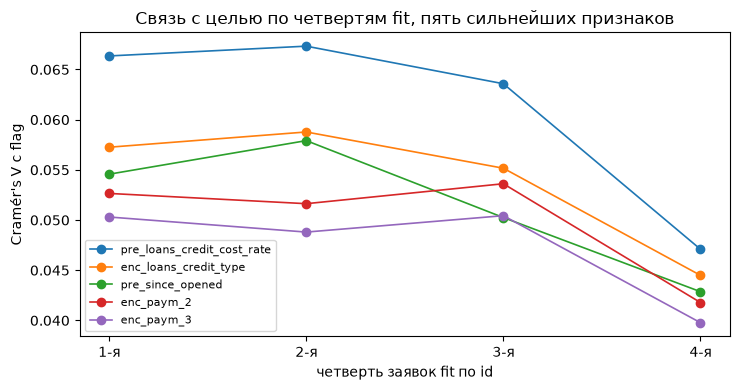

у признаков из топ-15 связь в четвёртой четверти слабее, чем в первой: 15 из 15
pre_since_opened: V с 0.0546 в первой четверти падает до 0.0429 в четвёртой
pre_loans_credit_cost_rate: V с 0.0663 падает до 0.0471


In [4]:
def v_by_quarter(column: str) -> list[float]:
    """Cramér's V колонки с flag внутри каждой четверти заявок fit."""
    counts = quarter_rows[column]
    positives = quarter_positives[column]
    values = []
    for index in range(4):
        visible = counts[index] > 0
        table = np.vstack(
            [counts[index][visible] - positives[index][visible], positives[index][visible]]
        )
        values.append(cramers_v(table))
    return values


figure, axis = plt.subplots(figsize=(7.5, 4))
for column in signal["признак"].head(5):
    axis.plot(np.arange(1, 5), v_by_quarter(column), marker="o", linewidth=1.2, label=column)
axis.set_xticks(np.arange(1, 5))
axis.set_xticklabels(["1-я", "2-я", "3-я", "4-я"])
axis.set_xlabel("четверть заявок fit по id")
axis.set_ylabel("Cramér's V с flag")
axis.set_title("Связь с целью по четвертям fit, пять сильнейших признаков")
axis.legend(fontsize=8)
figure.tight_layout()
plt.show()

falling = [
    column for column in signal["признак"].head(15) if v_by_quarter(column)[3] < v_by_quarter(column)[0]
]
print(f"у признаков из топ-15 связь в четвёртой четверти слабее, чем в первой: {len(falling)} из 15")
opened = v_by_quarter("pre_since_opened")
print(f"pre_since_opened: V с {opened[0]:.4f} в первой четверти падает до {opened[3]:.4f} в четвёртой")
cost = v_by_quarter("pre_loans_credit_cost_rate")
print(f"pre_loans_credit_cost_rate: V с {cost[0]:.4f} падает до {cost[3]:.4f}")


In [5]:
drift_rows = []
for column in FEATURES:
    counts = quarter_rows[column].astype(np.float64)
    share = counts / counts.sum(axis=1, keepdims=True)
    adjacent = [0.5 * float(np.abs(share[index] - share[index + 1]).sum()) for index in range(3)]
    smoothed = (counts + 0.5) / (
        counts.sum(axis=1, keepdims=True) + 0.5 * counts.shape[1]
    )
    first, last = smoothed[0], smoothed[3]
    psi = float(((first - last) * np.log(first / last)).sum())
    drift_rows.append(
        {
            "признак": column,
            "TV_1_2": round(adjacent[0], 4),
            "TV_2_3": round(adjacent[1], 4),
            "TV_3_4": round(adjacent[2], 4),
            "TV_макс": round(max(adjacent), 4),
            "PSI_1_4": round(psi, 4),
        }
    )
drift = pd.DataFrame(drift_rows).sort_values("TV_макс", ascending=False)
print("дрейф внутри fit (id < 2M), взвешен по строкам истории, а не по заявкам")
print("TV между соседними четвертями — основная метрика; PSI 1→4 — вспомогательная, сглаженная")
print("\nсдвиг распределения уровней между соседними четвертями, топ-15 по TV:")
print(drift.head(15).to_string(index=False))
print(
    f"\nмедиана TV_макс: {drift['TV_макс'].median():.4f}; "
    f"признаков с TV_макс >= 0.05: {int((drift['TV_макс'] >= 0.05).sum())} из {len(drift)}"
)


дрейф внутри fit (id < 2M), взвешен по строкам истории, а не по заявкам
TV между соседними четвертями — основная метрика; PSI 1→4 — вспомогательная, сглаженная

сдвиг распределения уровней между соседними четвертями, топ-15 по TV:
                   признак  TV_1_2  TV_2_3  TV_3_4  TV_макс  PSI_1_4
       pre_since_confirmed  0.0659  0.0751  0.0832   0.0832   0.0850
pre_loans_credit_cost_rate  0.0599  0.0463  0.0786   0.0786   0.0631
     enc_loans_credit_type  0.0168  0.0531  0.0236   0.0531   0.4602
          pre_since_opened  0.0452  0.0442  0.0409   0.0452   0.0858
           pre_till_pclose  0.0353  0.0234  0.0203   0.0353   0.0273
                 pre_pterm  0.0306  0.0175  0.0176   0.0306   0.0155
   pre_loans_next_pay_summ  0.0270  0.0168  0.0195   0.0270   0.0212
           pre_till_fclose  0.0249  0.0190  0.0192   0.0249   0.0235
                 pre_fterm  0.0240  0.0241  0.0112   0.0241   0.0135
          is_zero_loans530  0.0063  0.0220  0.0074   0.0220   0.0005
          

In [6]:
started = time.perf_counter()
PART_COUNTS: list[dict[str, np.ndarray]] = []
PART_POSITIVES: list[dict[str, np.ndarray]] = []
PART_ROWS: list[int] = []             # строки истории
PART_POSITIVE: list[int] = []         # положительные строки истории
PART_APPLICATIONS: list[int] = []
PART_APPLICATION_POSITIVE: list[int] = []

for part in TRAIN_PARTS[:8]:
    frame = pd.read_parquet(part).astype(np.int32)
    ids = frame["id"].to_numpy()
    labels = FLAGS_FIT.reindex(ids).to_numpy(dtype=np.float64)
    counts_part: dict[str, np.ndarray] = {}
    positives_part: dict[str, np.ndarray] = {}
    for column in FEATURES:
        values = frame[column].to_numpy()
        size = int(values.max()) + 1
        counts_part[column] = np.bincount(values, minlength=size)
        positives_part[column] = np.bincount(values, weights=labels, minlength=size)
    PART_COUNTS.append(counts_part)
    PART_POSITIVES.append(positives_part)
    application_ids = pd.unique(ids)
    PART_ROWS.append(len(ids))
    PART_POSITIVE.append(int(labels.sum()))
    PART_APPLICATIONS.append(len(application_ids))
    PART_APPLICATION_POSITIVE.append(int(FLAGS_FIT.reindex(application_ids).sum()))
    del frame
    gc.collect()

assert len(PART_COUNTS) == len(PART_POSITIVES) == 8
assert len(PART_ROWS) == len(PART_POSITIVE) == len(PART_APPLICATIONS) == 8
assert sum(PART_APPLICATIONS) == FIT_MAX

test_counts = {column: np.zeros(0, dtype=np.int64) for column in FEATURES}
test_rows = 0
for part in TEST_PARTS:
    frame = pd.read_parquet(part, columns=FEATURES).astype(np.int32)
    for column in FEATURES:
        values = frame[column].to_numpy()
        size = int(values.max()) + 1
        old = test_counts[column]
        counts = np.zeros(max(len(old), size), dtype=np.int64)
        counts[: len(old)] += old
        counts[:size] += np.bincount(values, minlength=size)
        test_counts[column] = counts
    test_rows += len(frame)
    del frame
    gc.collect()


def sum_counts(parts: list[dict[str, np.ndarray]]) -> dict[str, np.ndarray]:
    """Сумма счётчиков по партициям; длины дополняются нулями до максимума."""
    total = {}
    for column in FEATURES:
        size = max(len(part[column]) for part in parts)
        values = np.zeros(size, dtype=np.int64)
        for part in parts:
            counts = part[column]
            values[: len(counts)] += counts
        total[column] = values
    return total


def sum_positives(parts: list[dict[str, np.ndarray]]) -> dict[str, np.ndarray]:
    """Сумма положительных счётчиков; длины дополняются нулями до максимума."""
    total = {}
    for column in FEATURES:
        size = max(len(part[column]) for part in parts)
        values = np.zeros(size, dtype=np.float64)
        for part in parts:
            positives = part[column]
            values[: len(positives)] += positives
        total[column] = values
    return total


fit_counts = sum_counts(PART_COUNTS)
early_counts = sum_counts(PART_COUNTS[:6])
recent_counts = sum_counts(PART_COUNTS[6:8])
fit_positives = sum_positives(PART_POSITIVES)
early_positives = sum_positives(PART_POSITIVES[:6])
recent_positives = sum_positives(PART_POSITIVES[6:8])


def column_unseen(values: np.ndarray, table: np.ndarray) -> np.ndarray:
    """True там, где уровень отсутствует в fit, включая значения за длиной таблицы."""
    unseen = values >= len(table)
    inside = values < len(table)
    unseen[inside] = ~table[values[inside]]
    return unseen


def count_unseen(parts: list[Path]) -> int:
    """Строки, где хотя бы одно значение не встречалось в fit 0..7."""
    present = {column: fit_counts[column] > 0 for column in FEATURES}
    total = 0
    for part in parts:
        frame = pd.read_parquet(part, columns=FEATURES).astype(np.int32)
        unseen = np.zeros(len(frame), dtype=bool)
        for column in FEATURES:
            unseen |= column_unseen(frame[column].to_numpy(), present[column])
        total += int(unseen.sum())
        del frame
        gc.collect()
    return total


unseen_test = count_unseen(TEST_PARTS)

vocabulary_rows = []
for column in FEATURES:
    fit_levels = set(np.flatnonzero(fit_counts[column]).tolist())
    test_levels = set(np.flatnonzero(test_counts[column]).tolist())
    vocabulary_rows.append(
        {
            "признак": column,
            "уровней_fit": len(fit_levels),
            "уровней_test": len(test_levels),
            "только_в_test": len(test_levels - fit_levels),
        }
    )
vocabulary = pd.DataFrame(vocabulary_rows)

print(f"счётчики 8 fit-партиций и test собраны за {time.perf_counter() - started:.0f}s")
print(f"пик памяти: {peak_memory_gb():.2f} ГБ")
print("словарь уровней: fit = партиции 0..7; test = обе test-партиции")
print("холдаут в 03 кодируется ENCODERS[8] (статистика 0..7), test в 04 — ENCODERS[12] (0..11)")
print(
    f"строчный prior fit (положительные строки / строки истории): "
    f"{sum(PART_POSITIVE) / sum(PART_ROWS):.4f}; "
    f"доля заявок fit: {sum(PART_APPLICATION_POSITIVE) / sum(PART_APPLICATIONS):.4f}"
)
print(vocabulary.to_string(index=False))
print(
    f"\nпар «колонка × уровень» только в test: "
    f"{int(vocabulary['только_в_test'].sum())}"
)
print(
    f"строк test хотя бы с одним невиданным уровнем (vs fit 0..7): "
    f"{fmt_int(unseen_test)} из {fmt_int(test_rows)} строк истории"
)


счётчики 8 fit-партиций и test собраны за 21s
пик памяти: 3.00 ГБ
словарь уровней: fit = партиции 0..7; test = обе test-партиции
холдаут в 03 кодируется ENCODERS[8] (статистика 0..7), test в 04 — ENCODERS[12] (0..11)
строчный prior fit (положительные строки / строки истории): 0.0338; доля заявок fit: 0.0362
                      признак  уровней_fit  уровней_test  только_в_test
                           rn           55            57              2
             pre_since_opened           20            20              0
          pre_since_confirmed           18            17              0
                    pre_pterm           18            18              0
                    pre_fterm           17            17              0
              pre_till_pclose           17            17              0
              pre_till_fclose           16            16              0
       pre_loans_credit_limit           20            20              0
      pre_loans_next_pay_summ            7 

## Шаг 1. Что такое каждая строка

Прежде чем строить признаки, нужно понять, что строка истории значит. Проверяем
две гипотезы: строка — это снимок бюро по заявке, и последняя запись — это
текущее состояние заявки.

Если бы строки были снимками одного и того же бюро на разные даты, распределения
у разных позиций записи не различались бы. Меряем total variation между
распределениями уровней на первой и на последней записи заявки и сравниваем
с разбросом между двумя чередующимися половинами тех же строк (чётные и
нечётные строки; это не случайная выборка).


In [7]:
def read_part(part: Path, columns: list[str] | None = None) -> pd.DataFrame:
    """Читает одну партицию в int32. Больше одной партиции за раз в памяти не держим."""
    frame = pd.read_parquet(part, columns=columns)
    return frame.astype(np.int32)


def total_variation(left: np.ndarray, right: np.ndarray) -> float:
    """Половина суммы абсолютных разниц долей уровней."""
    size = max(len(left), len(right))
    left = np.pad(left.astype(float), (0, size - len(left)), constant_values=0.0)
    right = np.pad(right.astype(float), (0, size - len(right)), constant_values=0.0)
    return float(np.abs(left / left.sum() - right / right.sum()).sum() / 2)


assert total_variation(np.array([1]), np.array([0, 1])) == 1.0
assert total_variation(np.array([1, 1]), np.array([1, 1])) == 0.0


WATCHED = [
    "enc_loans_credit_status",
    "pre_till_pclose",
    "pre_util",
    "is_zero_util",
    "pre_loans_outstanding",
]

frame = read_part(TRAIN_PARTS[0], ["id", "rn", "fclose_flag", "pclose_flag", *WATCHED])
last_position = frame.groupby("id", sort=False)["rn"].transform("max").to_numpy()
first_rows = frame["rn"].to_numpy() == 1
last_rows = last_position == frame["rn"].to_numpy()
half = np.arange(len(frame)) % 2 == 0

rows = []
for column in WATCHED:
    values = frame[column].to_numpy()
    alternating_tv = total_variation(
        np.bincount(values[half], minlength=int(values.max()) + 1),
        np.bincount(values[~half], minlength=int(values.max()) + 1),
    )
    rows.append(
        {
            "колонка": column,
            "TV(rn=1, rn=max)": round(
                total_variation(
                    np.bincount(values[first_rows], minlength=int(values.max()) + 1),
                    np.bincount(values[last_rows], minlength=int(values.max()) + 1),
                ),
                4,
            ),
            "TV(чередующиеся половины)": round(alternating_tv, 4),
        }
    )
print(pd.DataFrame(rows).to_string(index=False))

print("\nдоли по позиции записи:")
print(
    frame.assign(
        позиция=np.select([first_rows, last_rows], ["rn=1", "rn=max"], default="промежуточные")
    )
    .groupby("позиция")[["fclose_flag", "pclose_flag", "is_zero_util"]]
    .mean()
    .round(4)
    .to_string()
)
print(f"\nпик памяти: {peak_memory_gb():.2f} ГБ")
del frame
_ = gc.collect()


                колонка  TV(rn=1, rn=max)  TV(чередующиеся половины)
enc_loans_credit_status            0.5912                  0.0011
        pre_till_pclose            0.5942                  0.0022
               pre_util            0.5256                  0.0014
           is_zero_util            0.5042                  0.0009
  pre_loans_outstanding            0.4650                  0.0012

доли по позиции записи:


               fclose_flag  pclose_flag  is_zero_util
позиция                                              
rn=1                0.1671       0.1448        0.8070
rn=max              0.4698       0.2702        0.2900
промежуточные       0.1957       0.1617        0.7599

пик памяти: 3.00 ГБ


### Вывод шага 1

TV между первой и последней записями в сотни раз больше TV между чередующимися
половинами тех же строк: 0.4650…0.5942 против 0.0009…0.0022. Значит, позиция
записи — не случайность: каждая строка — отдельный кредитный продукт, а
`rn = max` — последний продукт по номеру. Это не доказывает, что все поля
последней записи актуальны на дату заявки: `rn` задаёт порядок продукта, а не
дату и не полноту обновления.

Доли это подтверждают: на `rn = max` кредит открыт чаще (`fclose_flag` 0.4698
против 0.1671), а доля `is_zero_util = 1` при переходе от `rn = 1` к `rn = max`
падает с 0.8070 до 0.2900.

Отсюда рабочее правило: агрегировать историю и отдельно брать последнюю запись.
Первую запись нельзя смешивать с последней как «то же самое»; её собственный
вклад проверяется абляцией на шаге 5, а решение фиксируется после прогона.


## Шаг 2. Почему сырые коды нельзя сравнивать

Словарь соревнования (`description.xlsx`) сообщает, что значения `pre_*` разбиты на
интервалы, а номер каждого интервала присвоен **случайно**, и что значения `enc_*`
закодированы **случайными** номерами. Значит код уровня — ярлык, а не порядковая
величина: `pre_util = 7` не значит «больше», чем `pre_util = 2`.

Проверяем главное следствие: доля `flag = 1` по уровням должна сохраняться во
времени, если уровень что-то значит. Считаем доли на ранних партициях `0..5` и
поздних `6..7` и смотрим корреляцию и расхождение. Это диагностика переносимости
внутри train; холдаут не читается и в выборе кодировки не участвует.

Отдельно сверяем словарь с test — какие уровни есть в test, но не встречались в
fit. Это аудит будущего переноса, а не критерий выбора. Таблица ниже — по всем
60 колонкам-признакам, включая флаги `is_zero_*` и `*_flag`; три вырожденные
колонки (один уровень в срезе) в неё не попадают и печатаются под ней.


In [8]:
RISK_COLUMNS = [
    "pre_over2limit",
    "pre_util",
    "pre_loans_credit_cost_rate",
    "enc_loans_credit_status",
    "enc_loans_credit_type",
    "pre_maxover2limit",
    "pre_loans_credit_limit",
    "pre_since_opened",
    "pre_loans_next_pay_summ",
    "pre_loans_outstanding",
    "pre_loans_max_overdue_sum",
    "pre_pterm",
    "pre_fterm",
    "pre_till_pclose",
    "pre_till_fclose",
    "pre_since_confirmed",
]
PAYM_COLUMNS = [f"enc_paym_{index}" for index in range(25)]
ENCODED_COLUMNS = [*RISK_COLUMNS, *PAYM_COLUMNS]
print(f"колонок для кодировки уровней: {len(ENCODED_COLUMNS)} (из {len(FEATURES)} признаков)")


колонок для кодировки уровней: 41 (из 60 признаков)


In [9]:
rows = []
skipped = []
for column in FEATURES:
    early = early_counts[column]
    recent = recent_counts[column]
    size = max(len(early), len(recent))
    aligned_early = np.pad(early, (0, size - len(early)))
    aligned_recent = np.pad(recent, (0, size - len(recent)))
    aligned_early_positives = np.pad(
        early_positives[column], (0, size - len(early_positives[column]))
    )
    aligned_recent_positives = np.pad(
        recent_positives[column], (0, size - len(recent_positives[column]))
    )
    early_rate = aligned_early_positives / np.maximum(aligned_early, 1)
    recent_rate = aligned_recent_positives / np.maximum(aligned_recent, 1)
    supported = (aligned_early >= 5000) & (aligned_recent >= 1000)
    if supported.sum() < 2:
        skipped.append(column)
        continue
    rows.append(
        {
            "колонка": column,
            "уровней": int(supported.sum()),
            "corr(доли 0..5, доли 6..7)": round(
                float(np.corrcoef(early_rate[supported], recent_rate[supported])[0, 1]), 4
            ),
            "ср. расхождение долей": round(
                float(np.abs(early_rate[supported] - recent_rate[supported]).mean()), 5
            ),
            "разброс долей 6..7": round(
                float(recent_rate[supported].max() - recent_rate[supported].min()), 4
            ),
            "TV(0..5, 6..7)": round(total_variation(early, recent), 4),
            "TV(fit 0..7, test)": round(
                total_variation(fit_counts[column], test_counts[column]), 4
            ),
        }
    )
stability = pd.DataFrame(rows).sort_values("corr(доли 0..5, доли 6..7)")
print("устойчивость отображения уровень → доля (строки истории; train-only, без холдаута)")
print(stability.head(8).to_string(index=False))
print("\nхудшие по TV(fit 0..7, test) — аудит словаря ENCODERS[8], test в выборе не участвует:")
print(stability.sort_values("TV(fit 0..7, test)", ascending=False).head(5).to_string(index=False))
print(
    f"\nколонок с corr ниже 0.99: "
    f"{int((stability['corr(доли 0..5, доли 6..7)'] < 0.99).sum())} из {len(stability)}"
)
print(f"в таблицу не попали вырожденные колонки (один уровень в срезе): {', '.join(skipped)}")


устойчивость отображения уровень → доля (строки истории; train-only, без холдаута)
                колонка  уровней  corr(доли 0..5, доли 6..7)  ср. расхождение долей  разброс долей 6..7  TV(0..5, 6..7)  TV(fit 0..7, test)
  pre_loans_outstanding        5                      0.8765                0.00375              0.0127          0.0116              0.0267
pre_loans_next_pay_summ        7                      0.9324                0.00374              0.0104          0.0388              0.0592
           pre_loans530        5                      0.9420                0.00347              0.0157          0.0007              0.0008
    pre_since_confirmed       17                      0.9506                0.00318              0.0142          0.0807              0.1204
        pre_till_fclose       16                      0.9618                0.00362              0.0205          0.0315              0.0628
 pre_loans_credit_limit       20                      0.9773                0

### Вывод шага 2

Отображение «уровень → доля» в основном переносится с ранних партиций на поздние,
но не везде: `колонок с corr ниже 0.99` — 17 из 57 (счёт по 57 невырожденным
колонкам). Худшие в печати — `pre_loans_outstanding` 0.8765,
`pre_loans_next_pay_summ` 0.9324 и `pre_loans530` 0.9420. У
`pre_loans_outstanding` доли на уровнях плавают заметнее, поэтому кодировку для
неё стоит читать осторожно. У `pre_loans_credit_cost_rate` корреляция высокая
(0.9945), но TV(fit 0..7, test) — 0.1489: это разница словаря с test, а не
нестабильность внутри train.

Словарь уровней: 19 пар «колонка × уровень» есть только в test; невиданные уровни
редки: 57 строк из 4 724 601 строки test. Холдаут в этой диагностике не
участвует: доли считаются на партициях `0..5` и `6..7`, test — отдельный аудит
переноса.

TV(fit 0..7, test) в таблице — аудит словаря: у части колонок смесь уровней на
test заметно отличается. Это предупреждение о переносе, а не критерий выбора:
test в выборе признаков и кодировки не участвует.


## Шаг 3. Кодировка уровней

Раз код — ярлык, к нему нельзя прибавлять и сравнивать. Вместо этого каждый уровень
заменяется сглаженным логарифмом шансов:

```
LO[c][l] = ln( (k_l + ALPHA · p) / (n_l − k_l + ALPHA · (1 − p)) )
```

где `k_l` — положительные строки на уровне, `n_l` — все строки, `p` — строчный
prior (положительные строки истории / строки истории; на fit он равен 0.0338, а
доля заявок — 0.0362). `ALPHA = 200` сглаживает редкие уровни.

Кодировка строится OOF: для партиции `k` берутся счётчики партиций `0…k-1`,
партиция 0 получает нейтральный ноль. Уровни с `n_l < MIN_LEVEL_ROWS = 2000`
обнуляются: их оценка доли шумовая, поэтому используется нейтральный ноль, а не
log-odds по редким уровням. Уровень, не встретившийся в статистике кодировщика,
тоже получает ноль.

После этого `LO` — обычное число, которое можно усреднять по истории заявки.


In [10]:
def make_encoder(
    counts: dict[str, np.ndarray], positives: dict[str, np.ndarray], base_rate: float
) -> dict[str, np.ndarray]:
    """Строит отображение уровень → log-odds с обнулением редких уровней."""
    encoder = {}
    for column, column_counts in counts.items():
        column_positives = positives[column][: len(column_counts)]
        odds = np.log(
            (column_positives + ALPHA * base_rate)
            / (column_counts - column_positives + ALPHA * (1 - base_rate))
        )
        odds[column_counts < MIN_LEVEL_ROWS] = 0.0
        encoder[column] = odds.astype(np.float32)
    return encoder


def grow(values: np.ndarray, size: int) -> np.ndarray:
    """Дополняет массив до нужной длины; не обрезает."""
    if len(values) >= size:
        return values
    return np.pad(values, (0, size - len(values)))


def build_encoders(part_counts, part_positives, part_rows, part_positive,
                   columns, n_encoders: int = 9) -> list[dict[str, np.ndarray]]:
    """encoders[k] — по партициям 0..k-1; encoders[8] — по всем 8 fit-партициям."""
    encoders, rows, positives = [], 0, 0
    total_counts = {c: np.zeros(0, dtype=np.int64) for c in columns}
    total_positives = {c: np.zeros(0, dtype=np.float64) for c in columns}
    for k in range(n_encoders):
        if k == 0:
            encoders.append({c: np.zeros(1, dtype=np.float32) for c in columns})
        else:
            encoders.append(make_encoder(total_counts, total_positives,
                                         positives / rows))
        if k < n_encoders - 1:
            for c in columns:
                counts = part_counts[k][c].astype(np.int64)
                total_counts[c] = grow(total_counts[c], len(counts))
                total_counts[c][: len(counts)] += counts
                pos = part_positives[k][c].astype(np.float64)
                total_positives[c] = grow(total_positives[c], len(pos))
                total_positives[c][: len(pos)] += pos
            rows += part_rows[k]
            positives += part_positive[k]
    return encoders


ENCODERS = build_encoders(PART_COUNTS, PART_POSITIVES, PART_ROWS,
                          PART_POSITIVE, ENCODED_COLUMNS)
assert len(ENCODERS) == 9

print("строчный prior по партициям (положительные строки / строки истории):",
      ", ".join(f"{PART_POSITIVE[k] / PART_ROWS[k]:.4f}" for k in range(8)))
print("доля положительных заявок по партициям (справочно):",
      ", ".join(f"{PART_APPLICATION_POSITIVE[k] / PART_APPLICATIONS[k]:.4f}" for k in range(8)))
max_lengths = {k: max(len(ENCODERS[k][c]) for c in ENCODED_COLUMNS) for k in range(9)}
print("максимальная длина таблицы кодировщика по всем кодируемым колонкам:",
      ", ".join(f"{k}:{max_lengths[k]}" for k in range(9)))

for c in ENCODED_COLUMNS:
    lengths = [len(PART_COUNTS[k][c]) for k in range(8)]
    assert lengths == sorted(lengths), c

# PART_ROWS / PART_POSITIVE — строки истории, поэтому prior здесь строчный.
for k in (1, 8):
    expected = make_encoder(sum_counts(PART_COUNTS[:k]),
                            sum_positives(PART_POSITIVES[:k]),
                            sum(PART_POSITIVE[:k]) / sum(PART_ROWS[:k]))
    for c in ENCODED_COLUMNS:
        assert np.array_equal(ENCODERS[k][c], expected[c]), (k, c)
assert all((table == 0).all() for table in ENCODERS[0].values())

for k in (8,):
    source = fit_counts
    assert all(len(ENCODERS[k][c]) == len(source[c]) for c in ENCODED_COLUMNS)

print("аудит невиданных уровней: test против fit 0..7, см. ячейку словаря")

FIT_ENCODER = ENCODERS[8]


def spread_of(column: str) -> float:
    table = FIT_ENCODER[column]
    visible = fit_counts[column][: len(table)] >= MIN_LEVEL_ROWS
    if not visible.any():
        return 0.0
    return float(np.ptp(table[visible]))


spread = pd.DataFrame(
    {
        "колонка": list(FIT_ENCODER),
        "разброс_log_odds": [spread_of(column) for column in FIT_ENCODER],
    }
).sort_values("разброс_log_odds", ascending=False)
print("\nразброс log-odds по уровням ENCODERS[8] (статистика 0..7), топ-10:")
print(spread.head(10).round(3).to_string(index=False))
print("\nколонок с нулевым разбросом:", int((spread["разброс_log_odds"] == 0).sum()))


строчный prior по партициям (положительные строки / строки истории): 0.0289, 0.0298, 0.0325, 0.0339, 0.0375, 0.0351, 0.0361, 0.0360
доля положительных заявок по партициям (справочно): 0.0309, 0.0328, 0.0352, 0.0364, 0.0407, 0.0372, 0.0385, 0.0375
максимальная длина таблицы кодировщика по всем кодируемым колонкам: 0:1, 1:20, 2:20, 3:20, 4:20, 5:20, 6:20, 7:20, 8:20
аудит невиданных уровней: test против fit 0..7, см. ячейку словаря

разброс log-odds по уровням ENCODERS[8] (статистика 0..7), топ-10:
                   колонка  разброс_log_odds
   enc_loans_credit_status             1.863
                  pre_util             1.647
pre_loans_credit_cost_rate             1.578
     enc_loans_credit_type             1.552
            pre_over2limit             1.467
         pre_maxover2limit             1.396
    pre_loans_credit_limit             1.019
               enc_paym_18             1.003
               enc_paym_15             1.002
               enc_paym_20             1.001

ко

## Шаг 4. Сборка признаков заявки

Агрегация выполняется по одной партиции за раз: история читается по частям, а не
целиком, поэтому пик памяти в этом ноутбуке — 3.00 ГБ. Каждая из 12 партиций
содержит 250 000 заявок и всю историю каждой из них, поэтому результат
склеивается построчно. Матрица до выбора варианта — 99 колонок.


In [11]:
ZERO_COLUMNS = [
    "is_zero_loans5",
    "is_zero_loans530",
    "is_zero_loans3060",
    "is_zero_loans6090",
    "is_zero_loans90",
    "is_zero_util",
    "is_zero_over2limit",
    "is_zero_maxover2limit",
]
OVERDUE_BUCKETS = ["loans5", "loans530", "loans3060", "loans6090", "loans90"]
WINDOW = 3


def application_bounds(ids: np.ndarray, rn: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Границы блоков строк по заявкам с проверкой сплошности rn."""
    if np.any(np.diff(ids) < 0):
        raise ValueError("id внутри партиции не отсортированы")
    starts = np.flatnonzero(np.r_[True, np.diff(ids) != 0])
    ends = np.r_[starts[1:], len(ids)]
    if not (rn[starts] == 1).all() or not (rn[ends - 1] == ends - starts).all():
        raise ValueError("rn не образует 1..n хотя бы у одной заявки")
    return starts, ends


def segment_sum(values: np.ndarray, starts: np.ndarray) -> np.ndarray:
    return np.add.reduceat(values.astype(np.float32), starts)


def tail_sum(values: np.ndarray, starts: np.ndarray, ends: np.ndarray) -> np.ndarray:
    lengths = ends - starts
    tail_start = np.repeat(np.maximum(ends - WINDOW, starts), lengths)
    return segment_sum(
        np.where(np.arange(len(values)) >= tail_start, values, np.float32(0.0)), starts
    )


def encode(
    column: str, values: np.ndarray, encoder: dict[str, np.ndarray]
) -> np.ndarray:
    table = encoder[column]
    if values.size and int(values.max()) >= len(table):
        table = np.pad(table, (0, int(values.max()) + 1 - len(table)))
    return table[values]


In [12]:
def build_part(part: Path, encoder: dict[str, np.ndarray], cold_start: bool) -> pd.DataFrame:
    """Признаки одной заявки, индекс — id заявки."""
    frame = read_part(
        part, ["id", "rn", *ENCODED_COLUMNS, *ZERO_COLUMNS, "fclose_flag", "pclose_flag"]
    )
    ids = frame["id"].to_numpy()
    starts, ends = application_bounds(ids, frame["rn"].to_numpy())
    sizes = (ends - starts).astype(np.float32)
    window_denominator = np.minimum(sizes, np.float32(WINDOW))

    out: dict[str, np.ndarray] = {
        "n_records": sizes,
        "cold_start": np.full(len(starts), np.float32(cold_start), dtype=np.float32),
    }
    out["share_open"] = segment_sum(frame["fclose_flag"].to_numpy() == 1, starts) / sizes
    out["share_noplan"] = segment_sum(frame["pclose_flag"].to_numpy() == 1, starts) / sizes

    for column in ZERO_COLUMNS:
        tag = column.removeprefix("is_zero_")
        nonzero = segment_sum(frame[column].to_numpy() == 0, starts)
        out[f"nz_{tag}"] = nonzero
        out[f"nzshare_{tag}"] = nonzero / sizes

    ladder = np.zeros(len(frame), dtype=np.float32)
    severity = np.zeros(len(frame), dtype=np.float32)
    weighted = np.zeros(len(frame), dtype=np.float32)
    any_overdue = np.zeros(len(frame), dtype=bool)
    for position, tag in enumerate(OVERDUE_BUCKETS, start=1):
        overdue = frame[f"is_zero_{tag}"].to_numpy() == 0
        any_overdue |= overdue
        ladder += np.float32(position) * overdue
        if position > 1:
            severity += np.float32(position - 1) * overdue
        weighted += np.float32([2.0, 3.0, 4.0, 6.0, 8.0][position - 1]) * overdue
    out["overdue_ladder"] = segment_sum(ladder, starts)
    out["overdue_sev"] = segment_sum(severity, starts)
    out["overdue_sev530"] = segment_sum(weighted, starts)
    out["any_overdue"] = segment_sum(any_overdue, starts) / sizes
    out["any_overdue_last3"] = (
        tail_sum(any_overdue.astype(np.float32), starts, ends) / window_denominator
    )
    out["last_util_nz"] = (frame["is_zero_util"].to_numpy()[ends - 1] == 0).astype(np.float32)

    row_total = np.zeros(len(frame), dtype=np.float32)
    row_max = np.full(len(frame), -np.inf, dtype=np.float32)
    for column in RISK_COLUMNS:
        encoded = encode(column, frame[column].to_numpy(), encoder)
        row_total += encoded
        row_max = np.maximum(row_max, encoded)
        out[f"mean_{column}"] = segment_sum(encoded, starts) / sizes
        out[f"last3_{column}"] = tail_sum(encoded, starts, ends) / window_denominator
        out[f"last_{column}"] = encoded[ends - 1]
        out[f"first_{column}"] = encoded[starts]
    if not np.isfinite(row_max).all():
        raise ValueError("row_max содержит -inf: у заявки нет ни одной RISK-колонки")
    risk_count = np.float32(len(RISK_COLUMNS))
    out["RISK_mean"] = segment_sum(row_total, starts) / (sizes * risk_count)
    out["RISK_mean_all_max"] = segment_sum(row_max, starts) / sizes
    out["RISK_max"] = row_max[ends - 1]
    out["RISK_last3"] = tail_sum(row_total, starts, ends) / window_denominator / risk_count

    payment_sum = np.zeros(len(frame), dtype=np.float32)
    weighted_last = np.zeros(len(starts), dtype=np.float32)
    for index, column in enumerate(PAYM_COLUMNS, start=1):
        encoded = encode(column, frame[column].to_numpy(), encoder)
        payment_sum += encoded
        weighted_last += np.float32(1.0 / (1.0 + index)) * encoded[ends - 1]
    out["PAYM_mean"] = segment_sum(payment_sum, starts) / sizes
    out["PAYM_last"] = payment_sum[ends - 1]
    out["PAYM_first"] = payment_sum[starts]
    out["PAYM_wlast"] = weighted_last
    out["PAYM_recency"] = tail_sum(payment_sum, starts, ends) / window_denominator

    return pd.DataFrame(out, index=pd.Index(ids[starts], name="id"))


In [13]:
def build_matrix(parts, encoders, cold_start_flags) -> pd.DataFrame:
    frames = [
        build_part(part, encoders[k], cold_start_flags[k])
        for k, part in enumerate(parts)
    ]
    return pd.concat(frames, axis=0)


started = time.perf_counter()
MATRIX_OOF = build_matrix(TRAIN_PARTS[:8], ENCODERS[:8], [k == 0 for k in range(8)])
ALL_COLUMNS = list(MATRIX_OOF.columns)
gc.collect()

assert MATRIX_OOF.index.is_unique
assert MATRIX_OOF.index.max() == FIT_MAX - 1
assert MATRIX_OOF.shape == (FIT_MAX, 99)
assert not MATRIX_OOF.isna().any().any()
assert np.isfinite(MATRIX_OOF.to_numpy()).all()
assert "cold_start" in ALL_COLUMNS
assert int(MATRIX_OOF["cold_start"].sum()) == PART_SIZE
assert set(MATRIX_OOF["cold_start"].unique()) == {0.0, 1.0}
assert not any(c.startswith("rawlast") for c in ALL_COLUMNS)
print(
    f"MATRIX_OOF {MATRIX_OOF.shape}, "
    f"{MATRIX_OOF.memory_usage(deep=False).sum() / 2**30:.2f} ГБ, "
    f"{time.perf_counter() - started:.0f}s"
)

LADDER_ALL = {
    "overdue_ladder", "overdue_sev", "overdue_sev530",
    "any_overdue", "any_overdue_last3",
}
FEATURE_DROPS = {
    "control": {"nz_loans530", "nzshare_loans530"} | LADDER_ALL,
    "plus_counts": LADDER_ALL,
    "plus_recent_overdue": {"overdue_ladder", "overdue_sev", "overdue_sev530"},
    "plus_weighted_ladder": set(),
}


def select(name: str) -> list[str]:
    drops = FEATURE_DROPS[name]
    return [c for c in ALL_COLUMNS if c not in drops]


EXPECTED_SIZES = {"control": 92, "plus_counts": 94,
                  "plus_recent_overdue": 96, "plus_weighted_ladder": 99}
sizes = {name: len(select(name)) for name in FEATURE_DROPS}
assert sizes == EXPECTED_SIZES, sizes
print("размеры наборов признаков:", sizes)


MATRIX_OOF (2000000, 99), 0.75 ГБ, 10s
размеры наборов признаков: {'control': 92, 'plus_counts': 94, 'plus_recent_overdue': 96, 'plus_weighted_ladder': 99}


## Шаг 5. Сравнение вариантов

Сравнение идёт по заранее зафиксированной лестнице; каждый вариант добавляет одну
идею к предыдущему:

- **control** — 92 признака: агрегаты log-odds, флаги `is_zero_*` и счётчики
  `nz_*`, кроме `nz_loans530` и `nzshare_loans530`, без лестницы просрочек;
- **plus_counts** — 94: плюс `nz_loans530` и `nzshare_loans530`;
- **plus_recent_overdue** — 96: плюс `any_overdue` и `any_overdue_last3`;
- **plus_weighted_ladder** — 99: плюс `overdue_ladder`, `overdue_sev` и
  `overdue_sev530`.

Правило принятия ступени: средний прирост по фолдам 2–7 должен быть больше одной
стандартной ошибки (SE по разностям фолдов) и положителен не менее чем в 5 из 6
фолдов. Если ступень не принята, выбор останавливается на предыдущей.

Сырые коды последней записи не проверяются: это решение принято до прогона, а не
результат сравнения. Отвергнутые ступени не возвращаются в набор.

После выбора ступени проверяются два упрощения по тому же правилу, но с обратным
смыслом: упрощение принимается, если текущий набор не лучше упрощённого значимо
(то есть прирост текущего над упрощённым не больше SE или положителен менее чем в
5 из 6 фолдов). Упрощения: убрать `n_records`; убрать `first_*` и `PAYM_first`.

Модель одна и та же: `HistGradientBoostingClassifier`, обучение на `id < 2M`,
проверка на фолдах 2–7 внутри fit; фолды 2–7 — это обучение на 0.5…1.75 млн
заявок. Холдаут в этом сравнении не участвует. Ожидаемое число признаков и AUC —
ориентир, а не критерий: решение фиксирует правило.


In [14]:
LABELS_OOF = FLAGS_FIT.reindex(MATRIX_OOF.index).to_numpy()
assert len(LABELS_OOF) == len(MATRIX_OOF) and not np.isnan(LABELS_OOF).any()


def evaluate_cv(name, columns, matrix, labels) -> pd.DataFrame:
    values = matrix[columns].to_numpy(np.float32)
    ids = matrix.index.to_numpy()
    rows = []
    for fold in range(FOLD_FIRST, FOLD_LAST + 1):
        low, high = fold * PART_SIZE, (fold + 1) * PART_SIZE
        train = ids < low
        valid = (ids >= low) & (ids < high)
        assert train.sum() == low and valid.sum() == PART_SIZE and not (train & valid).any()
        model = HistGradientBoostingClassifier(**HGB_PARAMS)
        started = time.perf_counter()
        model.fit(values[train], labels[train])
        rows.append({
            "вариант": name, "фолд": fold, "признаков": len(columns),
            "auc": roc_auc_score(labels[valid], model.predict_proba(values[valid])[:, 1]),
            "деревьев": model.n_iter_, "секунд": round(time.perf_counter() - started, 1),
        })
        del model
        gc.collect()
    del values
    return pd.DataFrame(rows)


def accept_step(prev: pd.DataFrame, nxt: pd.DataFrame) -> bool:
    diff = (nxt.sort_values("фолд")["auc"].to_numpy()
            - prev.sort_values("фолд")["auc"].to_numpy())
    se = diff.std(ddof=1) / np.sqrt(len(diff))
    print(f"прирост {diff.mean():+.5f}, SE {se:.5f}, "
          f"положителен в {(diff > 0).sum()} из {len(diff)}")
    return bool(diff.mean() > se and (diff > 0).sum() >= 5)


def accept_simplification(current: pd.DataFrame, reduced: pd.DataFrame) -> bool:
    diff = (current.sort_values("фолд")["auc"].to_numpy()
            - reduced.sort_values("фолд")["auc"].to_numpy())
    se = diff.std(ddof=1) / np.sqrt(len(diff))
    print(f"текущий лучше упрощённого на {diff.mean():+.5f}, SE {se:.5f}, "
          f"лучше в {(diff > 0).sum()} из {len(diff)}")
    return not (diff.mean() > se and (diff > 0).sum() >= 5)


LADDER = ["control", "plus_counts", "plus_recent_overdue", "plus_weighted_ladder"]
CV = {}
for name in LADDER:
    CV[name] = evaluate_cv(name, select(name), MATRIX_OOF, LABELS_OOF)
    frame = CV[name]
    print(f"{name}: {len(select(name))} признаков, среднее AUC {frame['auc'].mean():.5f}, "
          f"n_iter_ {frame['деревьев'].tolist()}")

chosen = LADDER[0]
for lower, higher in zip(LADDER, LADDER[1:]):
    print(f"\nступень {higher} против {lower}:")
    if accept_step(CV[lower], CV[higher]):
        chosen = higher
    else:
        print(f"остановка: {higher} не принят")
        break
print(f"\nвыбранная ступень: {chosen}")

FINAL_VARIANT = chosen
FINAL_COLUMNS = select(chosen)

reduced = [column for column in FINAL_COLUMNS if column != "n_records"]
CV["without_n_records"] = evaluate_cv("without_n_records", reduced, MATRIX_OOF, LABELS_OOF)
print("\nупрощение without_n_records:")
if accept_simplification(CV[chosen], CV["without_n_records"]):
    FINAL_VARIANT = "without_n_records"
    FINAL_COLUMNS = reduced
    print("принято")
else:
    print("отклонено")

reduced = [column for column in FINAL_COLUMNS
           if not column.startswith("first_") and column != "PAYM_first"]
CV["without_first"] = evaluate_cv("without_first", reduced, MATRIX_OOF, LABELS_OOF)
print("\nупрощение without_first:")
if accept_simplification(CV[FINAL_VARIANT], CV["without_first"]):
    FINAL_VARIANT = "without_first"
    FINAL_COLUMNS = reduced
    print("принято")
else:
    print("отклонено")

CV_ALL = pd.concat(CV.values(), ignore_index=True)
print("\nCV по фолдам 2–7 (expanding window, OOF-кодировка):")
print(CV_ALL.to_string(index=False))

summary_rows = []
for name, frame in CV.items():
    ordered = frame.sort_values("фолд")
    summary_rows.append(
        {
            "вариант": name,
            "признаков": int(ordered["признаков"].iloc[0]),
            "среднее_AUC": round(float(ordered["auc"].mean()), 5),
            "SD_ddof0": round(float(ordered["auc"].std(ddof=0)), 5),
            "AUC_по_фолдам": " ".join(f"{value:.5f}" for value in ordered["auc"]),
            "n_iter_": " ".join(str(value) for value in ordered["деревьев"]),
        }
    )
CV_SUMMARY = pd.DataFrame(summary_rows)
print("\nсводка CV:")
print(CV_SUMMARY.to_string(index=False))

FINAL_CV = CV[FINAL_VARIANT]
CV_MEAN = float(FINAL_CV["auc"].mean())
CV_SD = float(FINAL_CV["auc"].std(ddof=0))
FINAL_DROP = sorted(set(ALL_COLUMNS) - set(FINAL_COLUMNS))
FINAL_FEATURES = len(FINAL_COLUMNS)

assert set(FINAL_COLUMNS) <= set(ALL_COLUMNS)
assert not any(c.startswith("rawlast") for c in FINAL_COLUMNS)
assert "cold_start" in FINAL_COLUMNS
assert FINAL_FEATURES == len(FINAL_COLUMNS)

print(f'\nFINAL_VARIANT = "{FINAL_VARIANT}"')
print(f"FINAL_DROP = {set(FINAL_DROP)}")
print(f"FINAL_FEATURES = {FINAL_FEATURES}")
print(f"CV_MEAN = {CV_MEAN:.5f}, CV_SD = {CV_SD:.5f}")


control: 92 признаков, среднее AUC 0.74348, n_iter_ [300, 300, 300, 300, 300, 300]


plus_counts: 94 признаков, среднее AUC 0.74738, n_iter_ [300, 300, 300, 300, 300, 300]


plus_recent_overdue: 96 признаков, среднее AUC 0.75028, n_iter_ [300, 300, 300, 300, 300, 300]


plus_weighted_ladder: 99 признаков, среднее AUC 0.74998, n_iter_ [300, 300, 300, 300, 300, 300]

ступень plus_counts против control:
прирост +0.00390, SE 0.00052, положителен в 6 из 6

ступень plus_recent_overdue против plus_counts:
прирост +0.00290, SE 0.00108, положителен в 5 из 6

ступень plus_weighted_ladder против plus_recent_overdue:
прирост -0.00031, SE 0.00026, положителен в 1 из 6
остановка: plus_weighted_ladder не принят

выбранная ступень: plus_recent_overdue



упрощение without_n_records:
текущий лучше упрощённого на +0.00036, SE 0.00031, лучше в 5 из 6
отклонено



упрощение without_first:
текущий лучше упрощённого на +0.00000, SE 0.00035, лучше в 4 из 6
принято

CV по фолдам 2–7 (expanding window, OOF-кодировка):
             вариант  фолд  признаков      auc  деревьев  секунд
             control     2         92 0.754820       300    21.1
             control     3         92 0.747912       300    28.2
             control     4         92 0.742432       300    36.4
             control     5         92 0.742085       300    44.0
             control     6         92 0.740632       300    50.1
             control     7         92 0.732979       300    57.7
         plus_counts     2         94 0.758197       300    21.3
         plus_counts     3         94 0.752389       300    29.1
         plus_counts     4         94 0.744239       300    36.9
         plus_counts     5         94 0.747715       300    43.9
         plus_counts     6         94 0.744646       300    49.7
         plus_counts     7         94 0.737101       300    57.1
 p

In [15]:
started = time.perf_counter()
MATRIX_HOLDOUT = build_matrix(TRAIN_PARTS[8:], [ENCODERS[8]] * 4, [False] * 4)
gc.collect()

assert MATRIX_HOLDOUT.index.is_unique
assert MATRIX_HOLDOUT.index.min() == FIT_MAX
assert MATRIX_HOLDOUT.shape == (1_000_000, 99)
assert not MATRIX_HOLDOUT.isna().any().any()
assert np.isfinite(MATRIX_HOLDOUT.to_numpy()).all()
assert int(MATRIX_HOLDOUT["cold_start"].sum()) == 0

HOLDOUT_TARGETS = pd.read_csv(
    DATA_DIR / "train_target.csv",
    skiprows=FIT_MAX + 1,
    header=None,
    names=["id", "flag"],
)
assert len(HOLDOUT_TARGETS) == 1_000_000
assert int(HOLDOUT_TARGETS["id"].iloc[0]) == FIT_MAX
LABELS_HOLDOUT = (
    HOLDOUT_TARGETS.set_index("id")["flag"]
    .reindex(MATRIX_HOLDOUT.index)
    .to_numpy()
)
assert not np.isnan(LABELS_HOLDOUT).any()

model = HistGradientBoostingClassifier(**HGB_PARAMS)
model.fit(MATRIX_OOF[FINAL_COLUMNS].to_numpy(np.float32), LABELS_OOF)
scores = model.predict_proba(MATRIX_HOLDOUT[FINAL_COLUMNS].to_numpy(np.float32))[:, 1]
HOLDOUT_N_ITER = model.n_iter_
print(
    f"финальная модель: {FINAL_FEATURES} признаков, обучение на "
    f"{fmt_int(len(MATRIX_OOF))} заявках, n_iter_ {HOLDOUT_N_ITER}, "
    f"{time.perf_counter() - started:.0f}s"
)
del model
gc.collect()

holdout_ids = MATRIX_HOLDOUT.index.to_numpy()
block_rows = []
for index, (low, high) in enumerate(HOLDOUT_BLOCKS):
    mask = (holdout_ids >= low) & (holdout_ids < high)
    block_rows.append(
        {
            "блок": index,
            "id_от": low,
            "id_до": high,
            "заявок": int(mask.sum()),
            "AUC": float(roc_auc_score(LABELS_HOLDOUT[mask], scores[mask])),
        }
    )
blocks = pd.DataFrame(block_rows)
assert len(blocks) == 8 and (blocks["заявок"] == 125_000).all()
HOLDOUT_MEAN = float(blocks["AUC"].mean())
HOLDOUT_SD = float(blocks["AUC"].std(ddof=0))
print("\nхолдаут [2 000 000, 3 000 000), восемь блоков по 125 000 заявок:")
print(blocks.round(5).to_string(index=False))
print(f"\nсреднее AUC: {HOLDOUT_MEAN:.6f}")
print(f"SD по блокам (ddof=0): {HOLDOUT_SD:.6f}")
print(f"минимум: {blocks['AUC'].min():.6f}, максимум: {blocks['AUC'].max():.6f}")
print(f"n_iter_: {HOLDOUT_N_ITER}")
print()
print(f'FINAL_VARIANT = "{FINAL_VARIANT}"')
print(f"FINAL_DROP = {set(FINAL_DROP)}")
print(f"FINAL_FEATURES = {FINAL_FEATURES}")
print(f"HOLDOUT_MEAN = {HOLDOUT_MEAN:.6f}")
print(f"HOLDOUT_SD = {HOLDOUT_SD:.6f}")

SUMMARY = {
    "variant": FINAL_VARIANT,
    "features": FINAL_FEATURES,
    "columns": FINAL_COLUMNS,
    "cv_mean": round(CV_MEAN, 6),
    "cv_sd": round(CV_SD, 6),
    "holdout_mean": round(HOLDOUT_MEAN, 6),
    "holdout_sd": round(HOLDOUT_SD, 6),
    "holdout_blocks": int(len(blocks)),
}
SUMMARY_PATH = REPO_ROOT / "data" / "processed" / "03_summary.json"
SUMMARY_PATH.parent.mkdir(parents=True, exist_ok=True)
SUMMARY_PATH.write_text(
    json.dumps(SUMMARY, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(f"записан {rel(SUMMARY_PATH)}")


финальная модель: 79 признаков, обучение на 2 000 000 заявках, n_iter_ 300, 62s



холдаут [2 000 000, 3 000 000), восемь блоков по 125 000 заявок:
 блок   id_от   id_до  заявок     AUC
    0 2000000 2125000  125000 0.74524
    1 2125000 2250000  125000 0.74618
    2 2250000 2375000  125000 0.75399
    3 2375000 2500000  125000 0.74382
    4 2500000 2625000  125000 0.72851
    5 2625000 2750000  125000 0.74151
    6 2750000 2875000  125000 0.71915
    7 2875000 3000000  125000 0.73474

среднее AUC: 0.739142
SD по блокам (ddof=0): 0.010409
минимум: 0.719149, максимум: 0.753993
n_iter_: 300

FINAL_VARIANT = "without_first"
FINAL_DROP = {'overdue_ladder', 'first_pre_pterm', 'first_enc_loans_credit_status', 'PAYM_first', 'first_pre_till_pclose', 'first_pre_since_opened', 'first_pre_loans_credit_cost_rate', 'first_pre_maxover2limit', 'first_pre_fterm', 'overdue_sev', 'first_pre_loans_credit_limit', 'first_pre_since_confirmed', 'overdue_sev530', 'first_pre_loans_max_overdue_sum', 'first_pre_till_fclose', 'first_enc_loans_credit_type', 'first_pre_util', 'first_pre_over2lim

### Вывод шага 5

Сводка CV по фолдам 2–7 (expanding window, OOF-кодировка):

| вариант | признаков | среднее AUC | SD (ddof=0) |
|---|---:|---:|---:|
| control | 92 | 0.74348 | 0.00670 |
| plus_counts | 94 | 0.74738 | 0.00665 |
| plus_recent_overdue | 96 | 0.75028 | 0.00493 |
| plus_weighted_ladder | 99 | 0.74998 | 0.00487 |
| without_n_records | 95 | 0.74993 | 0.00517 |
| without_first | 79 | 0.75028 | 0.00549 |

Отдельной кривой обучения нет: фолды 2–7 обучаются на 0.5…1.75 млн заявок, и
вывод CV выше показывает качество на каждом фолде; объём обучения и период
меняются одновременно.

**Лестница.** `plus_counts` против `control`: +0.00390, SE 0.00052, 6/6 —
принят. `plus_recent_overdue` против `plus_counts`: +0.00290, SE 0.00108, 5/6 —
принят. `plus_weighted_ladder` против `plus_recent_overdue`: -0.00031, SE
0.00026, 1/6 — отклонён; выбор остановлен на `plus_recent_overdue`.
`plus_weighted_ladder` (99) остаётся в таблице как измерение, но после остановки
как кандидат не рассматривался.

**Упрощения.** `without_n_records` против выбранного набора: текущий лучше на
+0.00036, SE 0.00031, 5/6 — по правилу one-SE преимущество есть, упрощение
отклонено; `n_records` остаётся. `without_first` против текущего: текущий лучше
на +0.00000, SE 0.00035, 4/6 — по тому же правилу преимущества нет, упрощение
принято; `first_*` и `PAYM_first` удалены, набор — 79 признаков. Это решение
правила, а не проверка статистической значимости.

Итог правила: `FINAL_VARIANT = "without_first"`, `FINAL_FEATURES = 79`.

**Холдаут.** На зафиксированном наборе из 79 признаков: среднее AUC `0.739142`,
SD по восьми блокам (ddof=0) `0.010409`, `n_iter_ = 300`. Блоки: 0.74524,
0.74618, 0.75399, 0.74382, 0.72851, 0.74151, 0.71915, 0.73474; минимум
`0.719149`, максимум `0.753993`. Среднее на холдауте ниже CV-среднего 0.750282;
это согласуется с тем, что холдаут — более поздний отрезок. Холдаут не
участвовал в выборе набора.


## Шаг 6. Что не сработало

Три старые идеи в этом репозитории не проверялись. Ниже они отмечены как
непроверенные: чисел по ним здесь нет, и выводы по ним не делаются. Проверяется
только `n_records` — его измерение приведено в ячейке ниже.

- **Число различных уровней у заявки** и **«уровень изменился между первой и
  последней записью»**: в этом репозитории не проверялись.
- **Экспоненциальное затухание весов по `rn`** вместо жёсткого окна последних трёх
  записей: в этом репозитории не проверялось.
- **25 колонок `enc_paym_*` по отдельности** вместо одного среднего: в этом
  репозитории не проверялось.

**`n_records`.** Как одиночный признак он даёт среднее AUC `0.4605` по фолдам 2–7 —
ниже 0.5, то есть более длинная история в этих данных связана с меньшей долей
`flag = 1`, а не с большей. Средняя длина истории у заявок с `flag = 0` —
8.465 записи, с `flag = 1` — 7.894. Правило упрощения **оставило** `n_records` в
финальном наборе: `without_n_records` отклонено, потому что текущий набор лучше
упрощённого на +0.00036 (SE 0.00031, 5/6). Это не вывод о полезности `n_records` в
других наборах. Для сравнения: лучший одиночный признак — `RISK_mean`, `0.6718`.


In [16]:
record_frame = pd.DataFrame(
    {"n_records": MATRIX_OOF["n_records"].to_numpy(), "flag": LABELS_OOF},
    index=MATRIX_OOF.index,
)
by_flag = record_frame.groupby("flag")["n_records"].agg(["mean", "median", "size"])
print("записей на заявку в разрезе flag (fit, id < 2M):")
print(by_flag.round(3).to_string())
gap = float(by_flag["mean"].diff().dropna().iloc[0])
print(f"\nразница средних: {gap:+.3f} записи на заявку")

ids_oof = MATRIX_OOF.index.to_numpy()
fold_masks = {
    fold: (ids_oof >= fold * PART_SIZE) & (ids_oof < (fold + 1) * PART_SIZE)
    for fold in range(FOLD_FIRST, FOLD_LAST + 1)
}
single_rows = []
for column in ALL_COLUMNS:
    values = MATRIX_OOF[column].to_numpy()
    aucs = [
        roc_auc_score(LABELS_OOF[mask], values[mask]) for mask in fold_masks.values()
    ]
    single_rows.append(
        {
            "признак": column,
            "auc_mean": float(np.mean(aucs)),
            "auc_min": float(np.min(aucs)),
            "auc_max": float(np.max(aucs)),
        }
    )
single_frame = pd.DataFrame(single_rows).sort_values("auc_mean", ascending=False)
print("\ntop-15 одиночных признаков по среднему AUC на фолдах 2–7:")
print(single_frame.head(15).round(4).to_string(index=False))
single = dict(zip(single_frame["признак"], single_frame["auc_mean"]))
print(f"\nAUC n_records (среднее по фолдам 2–7): {single['n_records']:.4f}")


записей на заявку в разрезе flag (fit, id < 2M):
       mean  median     size
flag                        
0     8.465     7.0  1927680
1     7.894     6.0    72320

разница средних: -0.572 записи на заявку



top-15 одиночных признаков по среднему AUC на фолдах 2–7:
                        признак  auc_mean  auc_min  auc_max
                      RISK_mean    0.6718   0.6510   0.6937
              RISK_mean_all_max    0.6699   0.6488   0.6878
                     RISK_last3    0.6631   0.6470   0.6833
                      PAYM_mean    0.6571   0.6302   0.6747
                   PAYM_recency    0.6463   0.6251   0.6614
                  mean_pre_util    0.6238   0.6153   0.6390
                     PAYM_wlast    0.6190   0.6044   0.6297
                       RISK_max    0.6169   0.6010   0.6303
          mean_pre_since_opened    0.6102   0.5853   0.6359
                 last3_pre_util    0.6097   0.6013   0.6197
                      PAYM_last    0.6096   0.5945   0.6211
mean_pre_loans_credit_cost_rate    0.6021   0.5864   0.6118
     mean_enc_loans_credit_type    0.5957   0.5881   0.6003
         last3_pre_since_opened    0.5911   0.5744   0.6125
    mean_pre_loans_credit_limit    0.5881

## Шаг 7. Построчный разброс и уровень заявки

01 называет `pre_over2limit` одним из самых сильных признаков по построчному
разбросу: доли `flag = 1` по его уровням различаются сильнее, чем у соседних
признаков. Проверяем, из чего складывается этот разброс, — сколько строк стоит
за редкими уровнями и что даёт признак на уровне заявки.

Считаем на fit `0..7`, а не на партиции 0: партиция 0 — только 250 000 заявок,
её базовая доля и объём другие, поэтому она завышала вклад редких уровней.
На fit разброс создают не только редкие уровни: частые уровни тоже дают
разброс.

У `pre_over2limit` 15 из 20 уровней редкие (меньше 2000 строк), на них
приходится 0.08% строк; разброс доли `flag = 1` по всем уровням — 0.1264, а по
уровням от 2000 строк — 0.1014. Средний AUC признака `mean_pre_over2limit` по
фолдам 2–7 — `0.5207`. У `pre_loans3060` 6 редких уровней из 8 (0.01% строк), у
`pre_loans90` — 5 из 7 (0.01%); отдельных признаков для них в матрице нет.

Для `pre_over2limit` при кодировании уровни с `n_l < 2000` обнуляются, поэтому
в модель попадает только часть, подкреплённая строками. Ячейка ниже считает
редкие уровни на `fit_counts` (партиции `0..7`).


In [17]:
def application_auc(single_features: dict[str, float], column: str):
    """AUC одиночного признака на фолдах; константа и отсутствие — словами."""
    name = f"mean_{column}"
    if name not in single_features:
        return "нет признака"
    value = single_features[name]
    return round(value, 4) if np.isfinite(value) else "константа, AUC не определён"


rows = []
for column in ("pre_over2limit", "pre_loans3060", "pre_loans90"):
    counts = fit_counts[column]
    rare_rows = int(counts[(counts > 0) & (counts < MIN_LEVEL_ROWS)].sum())
    rows.append(
        {
            "колонка": column,
            "уровней": int((counts > 0).sum()),
            "редких уровней": int(((counts > 0) & (counts < MIN_LEVEL_ROWS)).sum()),
            "строк в редких уровнях, %": round(100 * rare_rows / counts.sum(), 2),
            "AUC (среднее по фолдам)": application_auc(single, column),
        }
    )
print("редкие уровни и разброс, который они создают на fit (порог MIN_LEVEL_ROWS = 2000):")
print(pd.DataFrame(rows).to_string(index=False))

counts = fit_counts["pre_over2limit"]
positives = fit_positives["pre_over2limit"]
visible = counts > 0
rates = positives[visible] / counts[visible]
frequent = counts[visible] >= MIN_LEVEL_ROWS
print("\npre_over2limit, доля flag=1 по уровням строк истории (fit 0..7):")
print(
    pd.DataFrame(
        {
            "уровень": np.flatnonzero(visible),
            "строк": counts[visible],
            "доля_flag1": rates.round(4),
            "доля_строк_fit, %": (100 * counts[visible] / counts.sum()).round(2),
            "учтён_в_разбросе": np.where(frequent, "да", "нет"),
        }
    ).to_string(index=False)
)
print(
    f"\nразброс по всем уровням: {rates.max() - rates.min():.4f}, "
    f"по уровням от {MIN_LEVEL_ROWS} строк: {rates[frequent].max() - rates[frequent].min():.4f}"
)
_ = gc.collect()


редкие уровни и разброс, который они создают на fit (порог MIN_LEVEL_ROWS = 2000):
       колонка  уровней  редких уровней  строк в редких уровнях, % AUC (среднее по фолдам)
pre_over2limit       20              15                       0.08                  0.5207
 pre_loans3060        8               6                       0.01            нет признака
   pre_loans90        7               5                       0.01            нет признака

pre_over2limit, доля flag=1 по уровням строк истории (fit 0..7):
 уровень    строк  доля_flag1  доля_строк_fit, % учтён_в_разбросе
       0      756      0.0913               0.00              нет
       1      738      0.1328               0.00              нет
       2 15825410      0.0336              93.70               да
       3      878      0.1253               0.01              нет
       4     1928      0.1317               0.01              нет
       5  1032936      0.0336               6.12               да
       6     4961      0.

In [18]:
assert set(FINAL_COLUMNS) <= set(ALL_COLUMNS)
assert len(FINAL_COLUMNS) == FINAL_FEATURES
assert not any(c.startswith("rawlast") for c in FINAL_COLUMNS)
assert "cold_start" in FINAL_COLUMNS
assert np.isfinite(MATRIX_OOF[FINAL_COLUMNS].to_numpy()).all()
assert np.isfinite(MATRIX_HOLDOUT[FINAL_COLUMNS].to_numpy()).all()
assert len(blocks) == 8 and (blocks["заявок"] == 125_000).all()
assert HOLDOUT_N_ITER == HGB_PARAMS["max_iter"] == 300
assert len(LABELS_HOLDOUT) == 1_000_000
assert SUMMARY_PATH.is_file()
print("проверки 03 пройдены")


проверки 03 пройдены


## Итог

CV-среднее выросло с 0.74348 у `control` до 0.75028 у `plus_recent_overdue`;
финальный набор после упрощения — `without_first`, 79 признаков, CV-среднее
0.75028, SD 0.00549. Принятые шаги — счётчики просрочек (`plus_counts`) и
`any_overdue`/`any_overdue_last3` (`plus_recent_overdue`); `plus_weighted_ladder`
отклонён, выбор остановлен. Сырые коды последней записи не проверялись.
Упрощение `without_n_records` отклонено, поэтому `n_records` остался; упрощение
`without_first` принято, поэтому `first_*` и `PAYM_first` удалены. Холдаут не
участвовал в выборе признаков, гиперпараметров и варианта; финальная оценка —
`0.739142` при SD `0.010409`. Ограничения — ниже.

## Ограничения

- Холдаут — не Kaggle-test. public/private-бейзлайн соревнования — другое
  разбиение, поэтому числа этого ноутбука с ним здесь не сравниваются; сравнение
  приведено в README.
- Гиперпараметры не подбирались: `HistGradientBoostingClassifier` во всех
  вариантах использовал один и тот же набор, поэтому сравнение относится к
  признакам, а не к настройке модели.
- Проверен один временной порядок; сравнения со случайными фолдами нет. Восемь
  блоков холдаута идут подряд по `id`, поэтому их разброс не равен стандартной
  ошибке независимых наблюдений.
- Холдаут использован один раз в этой версии; оценка относится к модели на 2 млн
  заявок. Финальная модель на 3 млн локально не измерена.
